In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def find_csv_filenames( path_to_dir, suffix=".csv" ):
    filenames = os.listdir(path_to_dir)
    return [ filename for filename in filenames if filename.endswith( suffix ) ]

COLOR1 = "#3B73A1"  # deep muted blue
COLOR2 = "#D9D9D9"  # 
COLOR3 = "#D55E00"  # vermillion

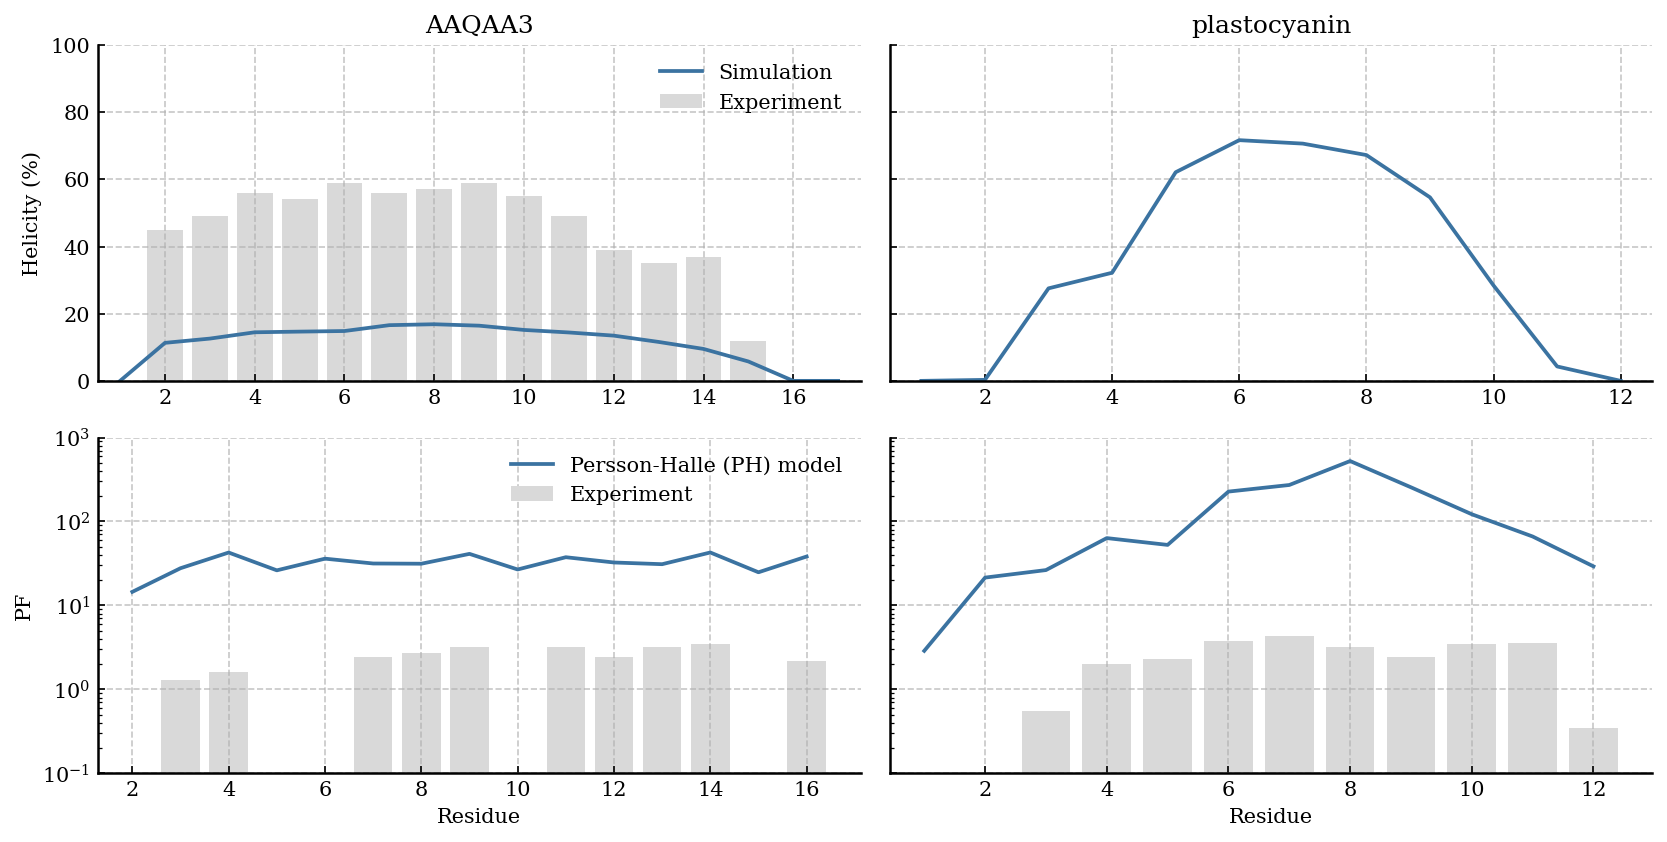

In [26]:
# Helicity and protection factors for AAQAA3 and plastocyanin peptides

COLOR1 = "#3B73A1"  # calculated
COLOR2 = "#D9D9D9"  # experimental

peptides = ['AAQAA3', 'plastocyanin']

fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), constrained_layout=True, sharey='row')

for col, peptide in enumerate(peptides):

    # Helicity
    with open(f'../../MD_DATA/{peptide}/dssp.dat') as f:
        dssp = np.array([line.strip() for line in f])

    residues = np.arange(len(dssp[0])) + 1
    helicity = np.mean(dssp_to_helicity(dssp), axis=0)

    ax = axes[0, col]

    if peptide == 'AAQAA3':
        exp_hel = pd.read_csv(f'../../ORTHOGONAL_EXP_DATA/{peptide}/helicity.csv', skiprows=8)
        ax.bar(exp_hel['Model_residue'], exp_hel['helicity(%)'], color=COLOR2, width=0.8, label='Experiment')

    ax.plot(residues, helicity * 100, color=COLOR1, linewidth=1.8, label='Simulation')
    ax.set_title(peptide)
    if peptide==peptides[0]:
        ax.set_ylabel('Helicity (%)')
    ax.set_ylim(0, 100)
    ax.set_xlim(0.5, residues[-1] + 0.5)

    # Protection factors
    exp = pd.read_csv(f'../../EXP_DATA/PF_Nguyen_2018/{peptide}.csv')
    Hcoord = np.load(f'../../WATER_MD_DATA/{peptide}/water_trajs_processed/AmideHcoord/amideH_water_coord_frames_traj1_0.26nm.npy')
    amides = np.loadtxt(f'../../WATER_MD_DATA/{peptide}/water_trajs_processed/AmideHcoord/amideresidues.txt').astype(int)

    fopen = np.mean(Hcoord >= 2, axis=0)
    calcPF = np.divide(1, fopen, out=np.full_like(fopen, np.nan, dtype=float), where=fopen > 0)

    ax = axes[1, col]
    ax.bar(exp['Model_residue'], exp['PF'], color=COLOR2, width=0.8, label='Experiment')
    ax.plot(amides, calcPF, color=COLOR1, linewidth=1.8, label='Persson-Halle (PH) model')
    ax.set_xlabel('Residue')
    if peptide==peptides[0]:
        ax.set_ylabel('PF')
    ax.set_yscale('log')
    ax.set_ylim(1e-1, 1e3)

for ax in axes.flat:
    ax.tick_params(axis='both', which='both', direction='in', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0, 0].legend(frameon=False)
axes[1, 0].legend(frameon=False)
plt.savefig('peptides_helicity_and_PF.pdf')
plt.show()

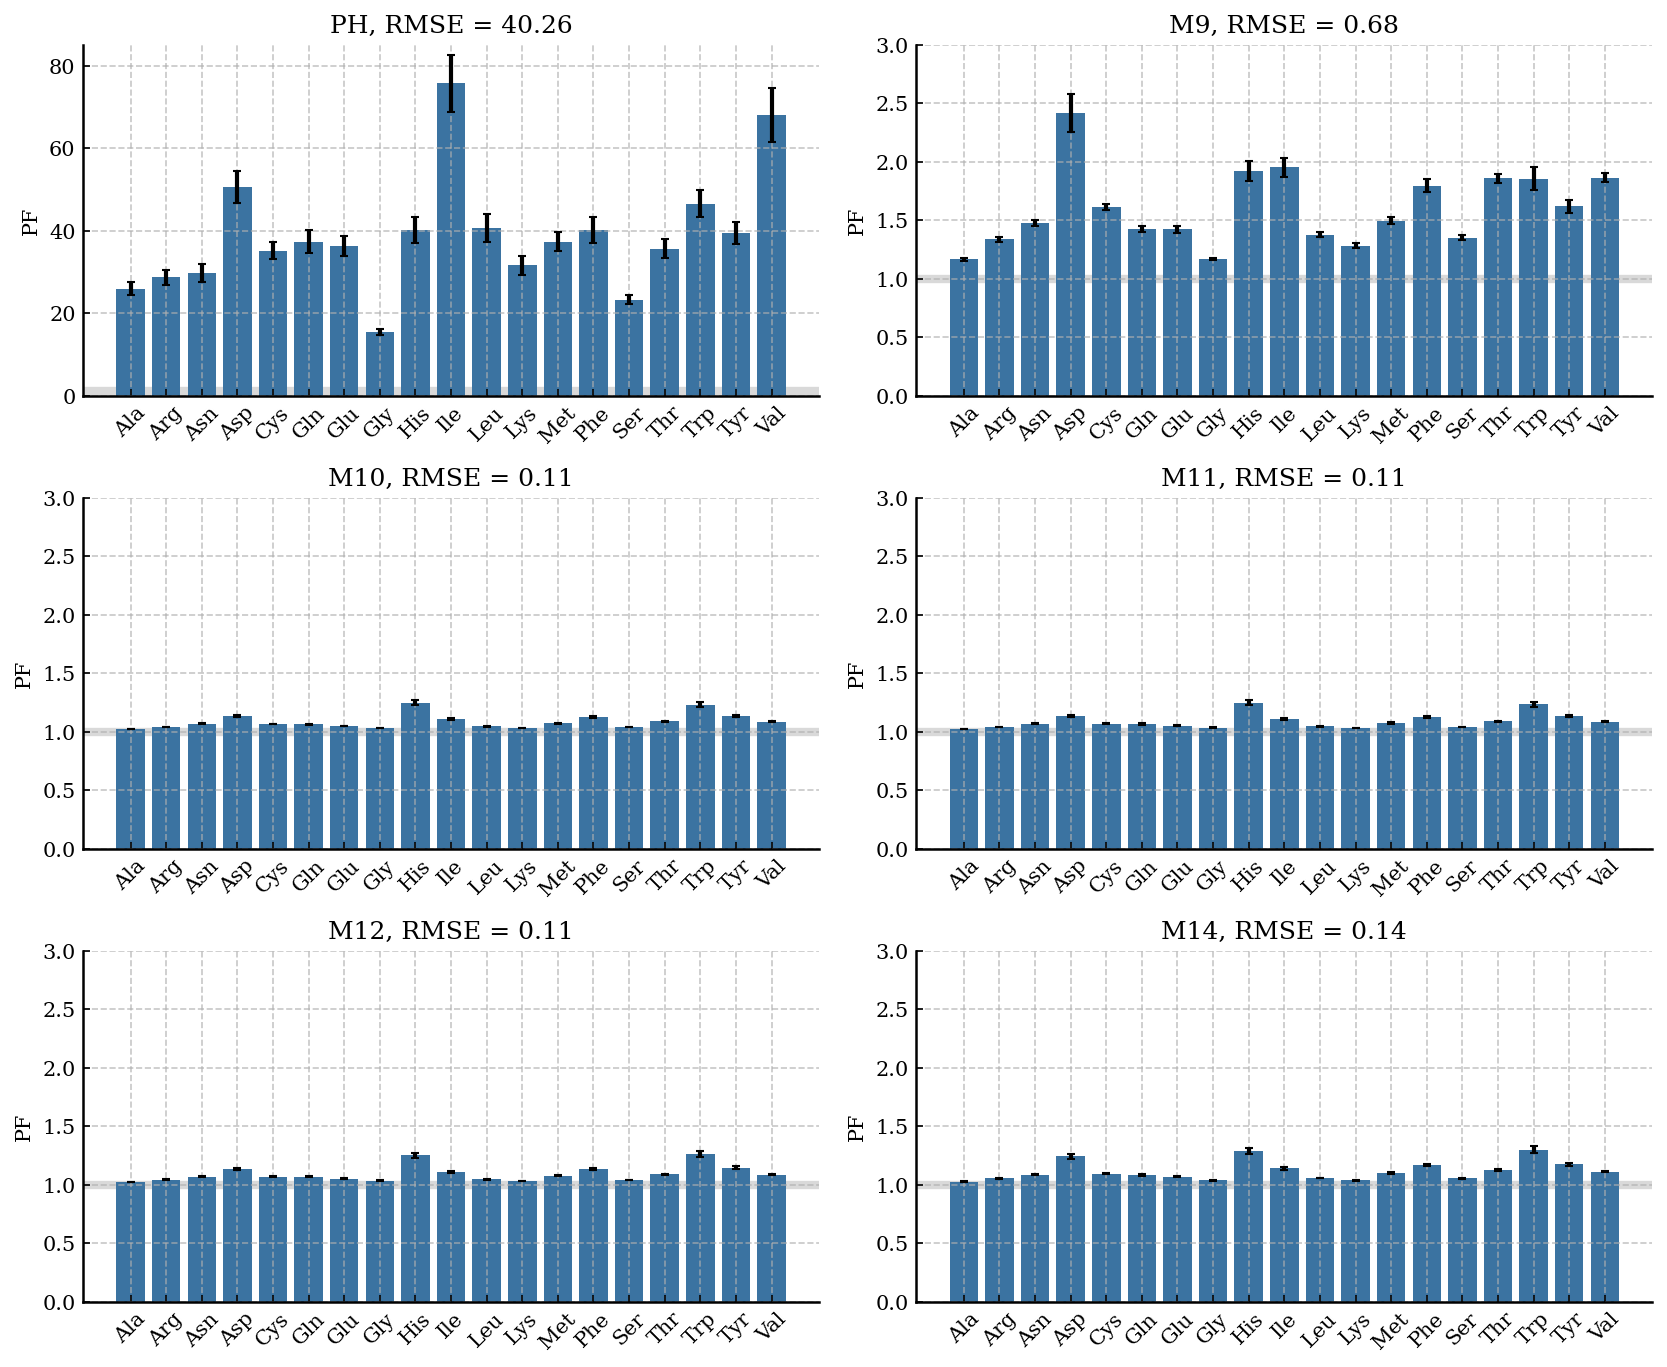

In [36]:
# Predicted PFs for AXA peptides using the PH and explicit open-state models

peptides = ['Ala', 'Arg', 'Asn', 'Asp', 'Cys', 'Gln', 'Glu', 'Gly', 'His',
            'Ile', 'Leu', 'Lys', 'Met', 'Phe', 'Ser', 'Thr', 'Trp', 'Tyr', 'Val']

model_names = ['PH', 'M9', 'M10', 'M11', 'M12', 'M14']

COLOR1 = "#3B73A1"  # calculated
COLOR2 = "#D9D9D9"  # expected PF = 1

file_path = '../../PEPTIDE_MD/analysis_AXA_tripeptides/'
csv_files = find_csv_filenames(file_path)

fig, axes = plt.subplots(3, 2, figsize=(11, 9), constrained_layout=True)
axes = axes.flatten()

for ax, model in zip(axes, model_names):

    matching_files = [file for file in csv_files if model in file and 'PF' in file]
    if len(matching_files) == 0:
        raise FileNotFoundError(f'No PF file found for model {model}')

    data = pd.read_csv(file_path + matching_files[0])
    data = data.set_index('AA').loc[peptides].reset_index()

    PF = data[f'PF_{model}']
    PF_error = data[f'PF_{model} ±']
    rmse = np.sqrt(np.mean((PF - 1.0) ** 2))

    ax.bar(data['AA'], PF, yerr=PF_error, color=COLOR1, capsize=2)
    ax.axhline(1.0, color=COLOR2, linewidth=4, zorder=0)
    ax.set_title(f'{model}, RMSE = {rmse:.2f}')
    ax.set_ylabel('PF')
    if model=='PH':
        ax.set_ylim(0,85)
    else:
        ax.set_ylim(0,3)
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='both', which='both', direction='in', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.savefig('AXA_peptide_PFs.pdf')
plt.show()